# Synthetic recovery of Fisher–KPP diffusion and proliferation

**Can a known migration coefficient and proliferation rate be recovered from noisy,
blurred, low-resolution observations?** This notebook provides a controlled 3D
experiment with ground truth, parameter confidence intervals, withheld forecasts,
and an empirical coverage audit. Choose **Run All** from the repository root.
The default 100 bootstrap fits and 60 independent recovery trials take about
1–3 minutes after the first Numba compilation, depending on the computer.

The phantom is a homogeneous 60 mm box, **not a patient scan or the BrainWeb
anatomy**. Its deliberately calibrated MRI-like signal makes two-parameter
recovery testable. The experiment does not establish clinical identifiability,
MRI-to-cellularity calibration, or biological validity of Fisher–KPP.

## Model and synthetic measurement experiment

Write $u=c/K$ for normalized viable cell density. With known, constant carrying
capacity $K$, homogeneous diffusion $D$ and proliferation $\rho$,

$$\partial_t u=D\nabla^2u+\rho u(1-u),\qquad
\nabla u\cdot\mathbf n=0\quad\text{on the box boundary}.$$

The initial condition is a fixed Gaussian with peak 0.2 and widths (5, 4, 5) mm,
centered at (−3, 2, 0) mm. Its finite-volume cell averages are integrated
analytically. It is smooth and untruncated, unlike the compact seed option in the
explorer. We reuse the explorer's conservative no-flux diffusion and exact
logistic-reaction kernel (`brainweb_kpp.model.advance`) with float64 arithmetic.
This experiment estimates a **single tissue migration coefficient**, not separate
white/gray matter coefficients and not the water ADC measured by diffusion MRI.

At each scan time $t_j$, the imaging operator $H$ applies a Gaussian point-spread
function (2 mm standard deviation), then averages disjoint 6 mm cubic voxels:

$$y_{jv}=H[u(D_*,\rho_*,t_j)]_v+\epsilon_{jv},\qquad
\epsilon_{jv}\overset{\mathrm{iid}}\sim\mathcal N(0,\sigma^2),\quad \sigma=0.03.$$

Noise is added **after** imaging, so the likelihood's independent-noise assumption
matches the experiment. Noisy values can lie outside [0,1] and are never clipped
for fitting. Only image color scales are limited. This Gaussian signal is a
cellularity proxy; it is not raw MRI magnitude data, which require a different
observation/noise model.

Scans at days **20, 40, 60** are used for fitting. Days **75, 90** are withheld.
The initial state, time origin, $K$, signal scale, point-spread function and noise
level are known. Uncertainty below is conditional on these strong assumptions.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import json
import nbformat
import platform
import time

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import scipy
from scipy.stats import binomtest, chi2
from numba import set_num_threads
from IPython.display import Markdown, display

from brainweb_kpp.inference import Phantom, SyntheticExperiment, fit_parameters

# Small repeated solves are faster with one Numba thread.
set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
ROOT = Path.cwd()
assert (ROOT / "pyproject.toml").exists(), "Start Jupyter in the repository root."
OUTPUT = ROOT / "outputs" / "synthetic_recovery"
OUTPUT.mkdir(parents=True, exist_ok=True)

SEED = 20261017
TRUE_PARAMETERS = np.array([0.300, 0.045])  # mm²/day, day⁻¹
SCAN_DAYS = np.array([20., 40., 60., 75., 90.])
N_TRAIN = 3
NOISE_SD = 0.03
BOUNDS = ((0.05, 0.01), (0.8, 0.09))  # optimizer constraints, not probability priors
N_BOOTSTRAP = 100
N_COVERAGE = 60  # increase to >= 500 for a more precise coverage assessment

phantom = Phantom()
inverse = SyntheticExperiment(phantom)  # dx = 2 mm, maximum dt = 0.25 day
truth = SyntheticExperiment(replace(phantom, dx_mm=1.0, dt_days=0.0625))
train_days, test_days = SCAN_DAYS[:N_TRAIN], SCAN_DAYS[N_TRAIN:]
noise_rng, bootstrap_rng, coverage_rng, forecast_rng = [
    np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(4)
]

def show_table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " +
                     " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

def save_figure(name):
    plt.savefig(OUTPUT / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

started = time.perf_counter()
print(f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}")
print(f"Training scans: {train_days}; withheld: {test_days}; seed: {SEED}")

Python 3.12.2, NumPy 2.5.4, SciPy 1.18.1
Training scans: [20. 40. 60.]; withheld: [75. 90.]; seed: 20261017


## Generate data independently of the inversion discretization

The generating simulation uses **1 mm / 0.0625 day** resolution; inversion uses
**2 mm / 0.25 day**. Both are stable over the allowed parameter range and use the
same PDE and numerical family. This avoids using identical discrete simulations
for truth and fitting, but remains a correctly specified synthetic biology and
imaging model. Shared structural assumptions make this substantially easier than
patient inference. We explicitly measure discretization discrepancy below.

Observation shape: (5, 10, 10, 10); 3,000 training measurements
Unclipped signal range: -0.099 to 0.572


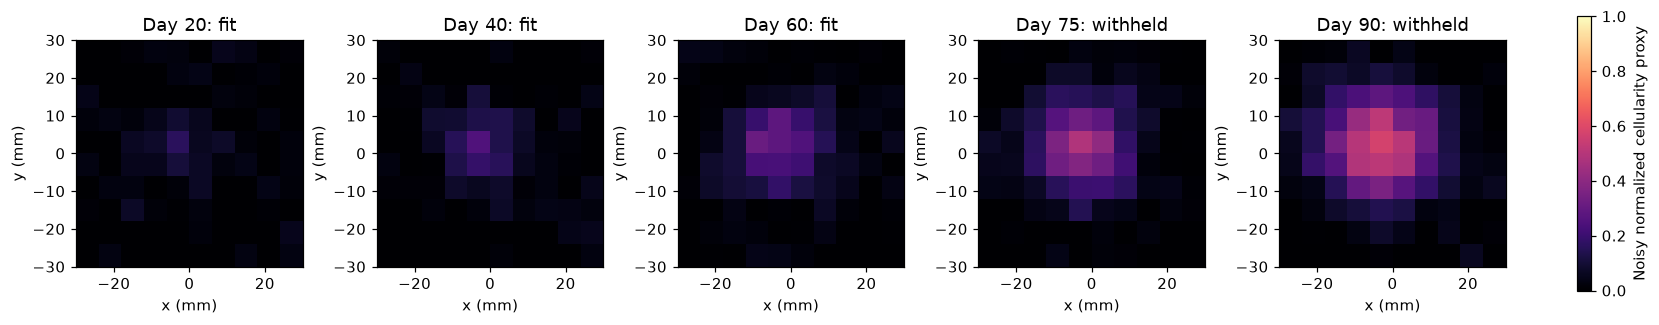

In [2]:
clean = truth.predict(*TRUE_PARAMETERS, SCAN_DAYS)
observed = clean + NOISE_SD * noise_rng.standard_normal(clean.shape)
train_observed = observed[:N_TRAIN].copy()
print(f"Observation shape: {observed.shape}; {train_observed.size:,} training measurements")
print(f"Unclipped signal range: {observed.min():.3f} to {observed.max():.3f}")

extent = [-phantom.width_mm / 2, phantom.width_mm / 2] * 2
mid = observed.shape[-1] // 2
fig, axes = plt.subplots(1, len(SCAN_DAYS), figsize=(15, 3.2), layout="constrained")
for j, ax in enumerate(axes):
    image = ax.imshow(observed[j, :, :, mid].T, origin="lower", extent=extent,
                      cmap="magma", vmin=0, vmax=1)
    ax.set(title=f"Day {SCAN_DAYS[j]:g}: {'fit' if j < N_TRAIN else 'withheld'}",
           xlabel="x (mm)", ylabel="y (mm)")
fig.colorbar(image, ax=axes, shrink=0.8, label="Noisy normalized cellularity proxy")
save_figure("observations")

## Estimate positive rates and local confidence intervals

Optimize $\theta=(\log D,\log\rho)$ by bounded Gaussian maximum likelihood:

$$\widehat\theta=\arg\min_\theta\frac12\sum_{j\in\mathrm{train},v}
\left[\frac{H[u(e^{\theta_1},e^{\theta_2},t_j)]_v-y_{jv}}{\sigma}\right]^2.$$

All training voxels are used; there is no truth-based or noisy-threshold ROI
selection. Three starting guesses check convergence. Bounds enforce a broad
positive search region; **no Bayesian prior** is used. The weighted residual
Jacobian $J$ gives the local approximation
$\mathrm{Cov}(\widehat\theta)\approx(J^TJ)^{-1}$. Marginal 95% Wald confidence
intervals are $\exp[\widehat\theta_i\pm1.96\sqrt{\mathrm{Cov}_{ii}}]$.
The noise scale is known, so this covariance is not multiplied by residual
variance. Rank deficiency raises an error; boundary fits are flagged.

These are asymptotic **confidence intervals**, conditional on the measurement
and initialization model. They do not account for unknown noise, registration,
segmentation, initialization, $K$, imaging calibration or structural model error.

In [3]:
starts = [(0.12, 0.02), (0.3, 0.04), (0.65, 0.075)]
fits = [fit_parameters(inverse, train_days, train_observed, NOISE_SD,
                       start=s, bounds=BOUNDS) for s in starts]
fit = min(fits, key=lambda f: np.sum(f.standardized_residuals**2))
if any(f.at_bound for f in fits):
    raise RuntimeError("A fit is at a bound; revisit the bounds before interpreting Wald intervals.")
show_table(["Start (D, ρ)", "Estimated D", "Estimated ρ", "Residual RMS / σ"], [
    [str(s), f"{f.parameters[0]:.6f}", f"{f.parameters[1]:.6f}",
     f"{np.sqrt(np.mean(f.standardized_residuals**2)):.3f}"]
    for s, f in zip(starts, fits)])
show_table(["Parameter", "Known", "Estimate", "Local 95% CI", "Relative error"], [
    [label, f"{true:g}", f"{estimate:.6f}", f"[{ci[0]:.6f}, {ci[1]:.6f}]",
     f"{100*(estimate/true-1):+.2f}%"]
    for label, true, estimate, ci in zip(
        ["D (mm²/day)", "ρ (day⁻¹)"], TRUE_PARAMETERS, fit.parameters, fit.intervals)])
print(f"Log-parameter correlation: {fit.correlation:+.3f}")
print(f"Weighted Jacobian singular values: {fit.singular_values.round(3)}")
print("Finite singular values and multi-start agreement are local diagnostics, not proof of global identifiability.")

| Start (D, ρ) | Estimated D | Estimated ρ | Residual RMS / σ |
| --- | --- | --- | --- |
| (0.12, 0.02) | 0.303262 | 0.045101 | 1.013 |
| (0.3, 0.04) | 0.303262 | 0.045101 | 1.013 |
| (0.65, 0.075) | 0.303262 | 0.045101 | 1.013 |

| Parameter | Known | Estimate | Local 95% CI | Relative error |
| --- | --- | --- | --- | --- |
| D (mm²/day) | 0.3 | 0.303262 | [0.272171, 0.337906] | +1.09% |
| ρ (day⁻¹) | 0.045 | 0.045101 | [0.044132, 0.046091] | +0.22% |

Log-parameter correlation: +0.540
Weighted Jacobian singular values: [107.892  18.011]
Finite singular values and multi-start agreement are local diagnostics, not proof of global identifiability.


## Parametric bootstrap and joint uncertainty

Generate new training observations from the **fitted** imaging model and refit
both parameters. Percentiles of these estimates give marginal bootstrap
confidence intervals. All trials are retained; a failed or boundary fit stops
the notebook rather than being silently dropped. The joint scatter reveals
parameter dependence. The ellipse is the *local joint* 95% approximation
($\chi^2_2$ cutoff), distinct from marginal 95% intervals.

Bootstrap fits: 25/100


Bootstrap fits: 50/100


Bootstrap fits: 75/100


Bootstrap fits: 100/100


| Parameter | Known | Bootstrap 95% CI | Known value inside? |
| --- | --- | --- | --- |
| D (mm²/day) | 0.3 | [0.272571, 0.335068] | True |
| ρ (day⁻¹) | 0.045 | [0.044295, 0.046042] | True |

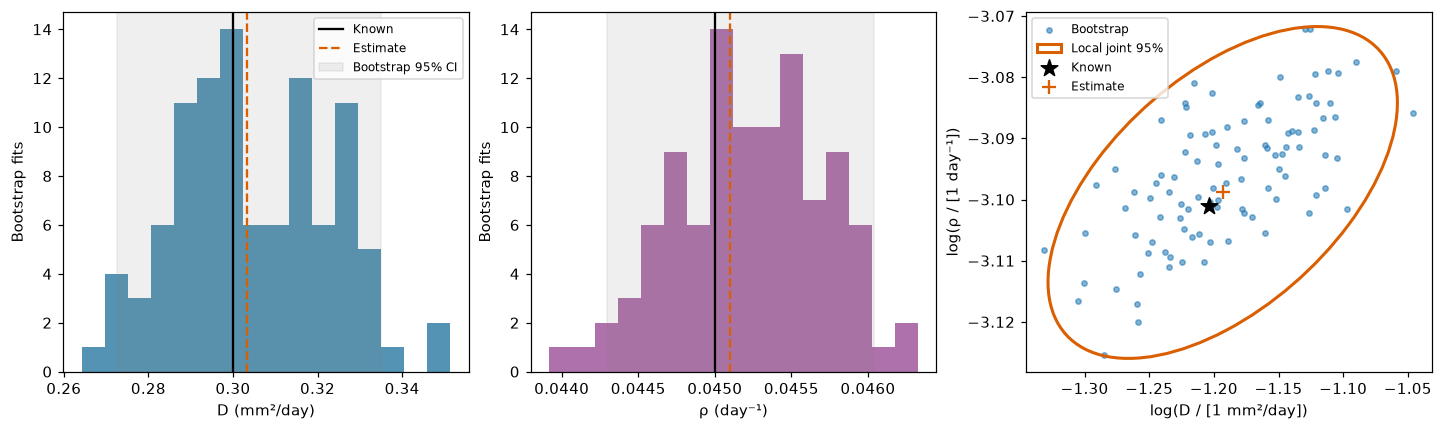

In [4]:
fitted_training = inverse.predict(*fit.parameters, train_days)
bootstrap_parameters = np.empty((N_BOOTSTRAP, 2))
for b in range(N_BOOTSTRAP):
    sample = fitted_training + NOISE_SD * bootstrap_rng.standard_normal(fitted_training.shape)
    boot_fit = fit_parameters(inverse, train_days, sample, NOISE_SD,
                              start=fit.parameters, bounds=BOUNDS)
    if boot_fit.at_bound:
        raise RuntimeError(f"Bootstrap fit {b} reached a bound; intervals need review.")
    bootstrap_parameters[b] = boot_fit.parameters
    if (b + 1) % 25 == 0:
        print(f"Bootstrap fits: {b + 1}/{N_BOOTSTRAP}", flush=True)
bootstrap_ci = np.quantile(bootstrap_parameters, [0.025, 0.975], axis=0).T
show_table(["Parameter", "Known", "Bootstrap 95% CI", "Known value inside?"], [
    [name, f"{value:g}", f"[{ci[0]:.6f}, {ci[1]:.6f}]", str(ci[0] <= value <= ci[1])]
    for name, value, ci in zip(["D (mm²/day)", "ρ (day⁻¹)"], TRUE_PARAMETERS, bootstrap_ci)])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for k, ax in enumerate(axes[:2]):
    ax.hist(bootstrap_parameters[:, k], bins=16, alpha=0.8, color=["#2978a0", "#9b4d96"][k])
    ax.axvline(TRUE_PARAMETERS[k], color="black", label="Known")
    ax.axvline(fit.parameters[k], color="#d95f02", linestyle="--", label="Estimate")
    ax.axvspan(*bootstrap_ci[k], color="gray", alpha=0.12, label="Bootstrap 95% CI")
    ax.set(xlabel=["D (mm²/day)", "ρ (day⁻¹)"][k], ylabel="Bootstrap fits")
axes[0].legend(fontsize=8)
ax = axes[2]
log_boot = np.log(bootstrap_parameters)
ax.scatter(log_boot[:, 0], log_boot[:, 1], s=12, alpha=0.55, label="Bootstrap")
eigenvalues, eigenvectors = np.linalg.eigh(fit.log_covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
width, height = 2 * np.sqrt(chi2.ppf(0.95, 2) * eigenvalues)
ax.add_patch(Ellipse(np.log(fit.parameters), width, height, angle=angle,
                     fill=False, edgecolor="#d95f02", linewidth=2, label="Local joint 95%"))
ax.scatter(*np.log(TRUE_PARAMETERS), marker="*", s=130, c="black", label="Known")
ax.scatter(*np.log(fit.parameters), marker="+", s=80, c="#d95f02", label="Estimate")
ax.set(xlabel="log(D / [1 mm²/day])", ylabel="log(ρ / [1 day⁻¹])")
ax.legend(fontsize=8)
save_figure("parameter_uncertainty")

## Forecast withheld scans, with parameter and observation uncertainty

No day-75 or day-90 measurement enters fitting or bootstrap recovery.
Propagate every bootstrap parameter pair through the forward model. Percentile
bands describe approximate pointwise confidence in the **noise-free mean
signal**. Adding independent new measurement noise gives approximate pointwise
**prediction intervals for a new observed scan**. They are wider and have a
different meaning. They are not simultaneous bands over the entire image.

Predictive Monte Carlo resamples the 100 fitted bootstrap trajectories and adds
new noise 1,000 times; this reduces noise-quantile error without additional PDE
solves. Increasing bootstrap fits improves parameter-tail precision.

| Withheld day | RMSE vs clean truth | RMSE vs noisy scan | Voxel fraction in 95% prediction interval |
| --- | --- | --- | --- |
| 75 | 0.00047 | 0.03036 | 94.0% |
| 90 | 0.00084 | 0.03018 | 94.6% |

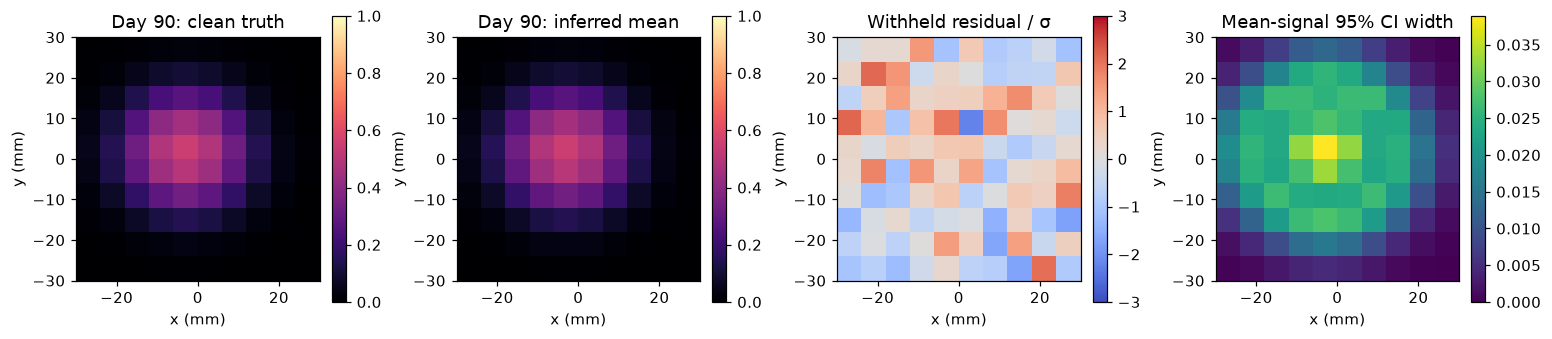

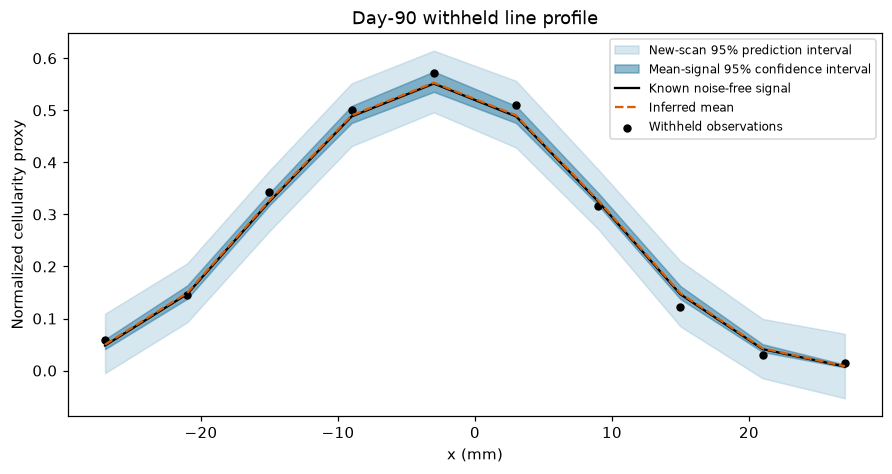

In [5]:
predicted = inverse.predict(*fit.parameters, SCAN_DAYS)
bootstrap_predictions = np.array([inverse.predict(*p, SCAN_DAYS)
                                  for p in bootstrap_parameters])
mean_band = np.quantile(bootstrap_predictions, [0.025, 0.975], axis=0)
replicate_predictions = bootstrap_predictions[
    forecast_rng.integers(N_BOOTSTRAP, size=1000)].copy()
replicate_predictions += NOISE_SD * forecast_rng.standard_normal(replicate_predictions.shape)
prediction_band = np.quantile(replicate_predictions, [0.025, 0.975], axis=0)
del replicate_predictions

clean_rmse = np.sqrt(np.mean((predicted - clean)**2, axis=(1, 2, 3)))
noisy_rmse = np.sqrt(np.mean((predicted - observed)**2, axis=(1, 2, 3)))
predictive_coverage = np.mean((observed >= prediction_band[0]) &
                              (observed <= prediction_band[1]), axis=(1, 2, 3))
show_table(["Withheld day", "RMSE vs clean truth", "RMSE vs noisy scan", "Voxel fraction in 95% prediction interval"], [
    [f"{SCAN_DAYS[j]:g}", f"{clean_rmse[j]:.5f}", f"{noisy_rmse[j]:.5f}",
     f"{predictive_coverage[j]:.1%}"] for j in range(N_TRAIN, len(SCAN_DAYS))])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained")
fields = [clean[-1], predicted[-1], (observed[-1] - predicted[-1]) / NOISE_SD,
          mean_band[1, -1] - mean_band[0, -1]]
for ax, field, title, cmap, limits in zip(axes, fields,
        ["Day 90: clean truth", "Day 90: inferred mean", "Withheld residual / σ", "Mean-signal 95% CI width"],
        ["magma", "magma", "coolwarm", "viridis"], [(0, 1), (0, 1), (-3, 3), (0, None)]):
    im = ax.imshow(field[:, :, mid].T, origin="lower", extent=extent,
                   cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set(title=title, xlabel="x (mm)", ylabel="y (mm)")
    fig.colorbar(im, ax=ax, shrink=0.7)
save_figure("withheld_day90")

coords = (np.arange(observed.shape[1]) + 0.5) * phantom.voxel_mm - phantom.width_mm / 2
ix_y = np.argmin(np.abs(coords - phantom.seed_center_mm[1]))
line = (slice(None), ix_y, mid)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.fill_between(coords, prediction_band[0, -1][line], prediction_band[1, -1][line],
                color="#8dbbd3", alpha=0.35, label="New-scan 95% prediction interval")
ax.fill_between(coords, mean_band[0, -1][line], mean_band[1, -1][line],
                color="#2978a0", alpha=0.5, label="Mean-signal 95% confidence interval")
ax.plot(coords, clean[-1][line], color="black", label="Known noise-free signal")
ax.plot(coords, predicted[-1][line], "--", color="#d95f02", label="Inferred mean")
ax.scatter(coords, observed[-1][line], c="black", s=20, label="Withheld observations")
ax.set(xlabel="x (mm)", ylabel="Normalized cellularity proxy", title="Day-90 withheld line profile")
ax.legend(fontsize=8)
save_figure("forecast_intervals")

## Independent repeated-noise validation against known parameters

One interval containing the known value is not evidence of 95% coverage.
Generate **60 independent noisy datasets from the fine-grid ground truth**,
fit each using only the early scans, and record bias, RMSE and the fraction of
local 95% intervals covering the true rate. Exact binomial 95% intervals show
how imprecise a small coverage audit is. This audits the **local Jacobian
intervals**; it does not validate bootstrap coverage, which would need a nested
bootstrap or a larger separate study. Trials share biology and initialization
and vary only measurement noise. They are not a virtual patient cohort.

Independent recovery trials: 20/60


Independent recovery trials: 40/60


Independent recovery trials: 60/60


| Parameter | Bias | RMSE | Local 95% CI coverage | 95% binomial CI for coverage |
| --- | --- | --- | --- | --- |
| D (mm²/day) | +0.002637 | 0.017121 | 59/60 (98.3%) | [91.1%, 100.0%] |
| ρ (day⁻¹) | +0.000000 | 0.000448 | 60/60 (100.0%) | [94.0%, 100.0%] |

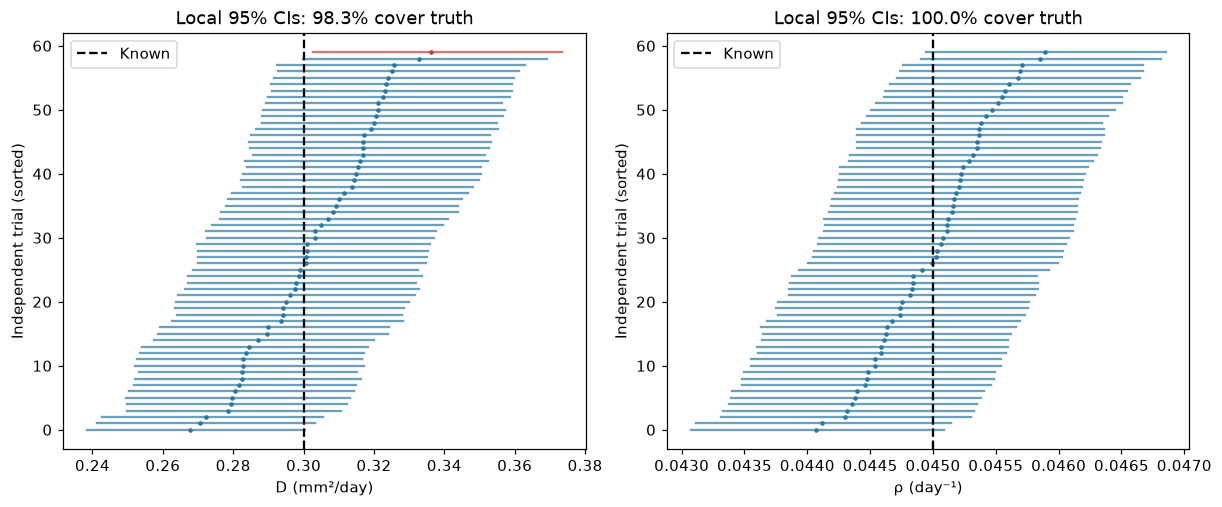

In [6]:
recovered = np.empty((N_COVERAGE, 2))
coverage_intervals = np.empty((N_COVERAGE, 2, 2))
for r in range(N_COVERAGE):
    replicate = clean[:N_TRAIN] + NOISE_SD * coverage_rng.standard_normal(train_observed.shape)
    trial = fit_parameters(inverse, train_days, replicate, NOISE_SD,
                           start=(0.25, 0.04), bounds=BOUNDS)
    if trial.at_bound:
        raise RuntimeError(f"Coverage trial {r} reached a bound; do not discard it.")
    recovered[r], coverage_intervals[r] = trial.parameters, trial.intervals
    if (r + 1) % 20 == 0:
        print(f"Independent recovery trials: {r + 1}/{N_COVERAGE}", flush=True)
contains = ((coverage_intervals[:, :, 0] <= TRUE_PARAMETERS) &
            (coverage_intervals[:, :, 1] >= TRUE_PARAMETERS))
coverage_counts = contains.sum(axis=0)
coverage_fraction = contains.mean(axis=0)
coverage_binomial = np.array([
    tuple(binomtest(int(k), N_COVERAGE).proportion_ci(confidence_level=0.95, method="exact"))
    for k in coverage_counts])
bias = recovered.mean(axis=0) - TRUE_PARAMETERS
parameter_rmse = np.sqrt(np.mean((recovered - TRUE_PARAMETERS)**2, axis=0))
show_table(["Parameter", "Bias", "RMSE", "Local 95% CI coverage", "95% binomial CI for coverage"], [
    [name, f"{bias[k]:+.6f}", f"{parameter_rmse[k]:.6f}",
     f"{coverage_counts[k]}/{N_COVERAGE} ({coverage_fraction[k]:.1%})",
     f"[{coverage_binomial[k, 0]:.1%}, {coverage_binomial[k, 1]:.1%}]"]
    for k, name in enumerate(["D (mm²/day)", "ρ (day⁻¹)"])])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for k, ax in enumerate(axes):
    order = np.argsort(recovered[:, k])
    for row, index in enumerate(order):
        color = "#2978a0" if contains[index, k] else "#c63d32"
        ax.plot(coverage_intervals[index, k], [row, row], color=color, alpha=0.7)
        ax.plot(recovered[index, k], row, ".", color=color, markersize=4)
    ax.axvline(TRUE_PARAMETERS[k], color="black", linestyle="--", label="Known")
    ax.set(xlabel=["D (mm²/day)", "ρ (day⁻¹)"][k], ylabel="Independent trial (sorted)",
           title=f"Local 95% CIs: {coverage_fraction[k]:.1%} cover truth")
    ax.legend()
save_figure("coverage_audit")

## Numerical discrepancy and an identifiability negative control

Compare the inference grid against the finer generator at the known parameters,
and halve the inference time step. Report discrepancies in **observation space**
relative to both the known noise SD and the achieved forecast error. A low
per-voxel discrepancy alone does not guarantee negligible parameter bias when
many voxels are observed; the repeated-noise bias audit above is also needed.

With only a scan at time zero, $D$ and $\rho$ cannot be identified: the initial
state is fixed and its observation does not depend on either rate. The fitter
must reject this experiment rather than manufacture narrow intervals.

In [7]:
coarse_at_truth = inverse.predict(*TRUE_PARAMETERS, SCAN_DAYS)
half_dt = SyntheticExperiment(replace(phantom, dt_days=phantom.dt_days / 2))
half_dt_at_truth = half_dt.predict(*TRUE_PARAMETERS, SCAN_DAYS)
grid_rmse = np.sqrt(np.mean((coarse_at_truth - clean)**2, axis=(1, 2, 3)))
time_rmse = np.sqrt(np.mean((coarse_at_truth - half_dt_at_truth)**2, axis=(1, 2, 3)))
show_table(["Day", "Coarse vs fine RMSE", "RMSE / noise SD", "Halved-dt change RMSE"], [
    [f"{day:g}", f"{g:.6f}", f"{g / NOISE_SD:.3%}", f"{t:.6f}"]
    for day, g, t in zip(SCAN_DAYS, grid_rmse, time_rmse)])

try:
    fit_parameters(inverse, [0.0], inverse.predict(*TRUE_PARAMETERS, [0.0]), NOISE_SD)
except ValueError as error:
    assert "not locally identifiable" in str(error)
    print(f"Expected negative-control result: {error}")
else:
    raise AssertionError("Time-zero data must not identify diffusion or proliferation.")

| Day | Coarse vs fine RMSE | RMSE / noise SD | Halved-dt change RMSE |
| --- | --- | --- | --- |
| 20 | 0.000055 | 0.185% | 0.000006 |
| 40 | 0.000111 | 0.371% | 0.000012 |
| 60 | 0.000185 | 0.617% | 0.000023 |
| 75 | 0.000255 | 0.849% | 0.000039 |
| 90 | 0.000341 | 1.137% | 0.000062 |

Expected negative-control result: D and rho are not locally identifiable in this experiment


## Save reproducible results and interpret the limits

The files in `outputs/synthetic_recovery/` record settings, units, seeds, fitted
values, both interval estimates, independent-trial results, forecast metrics,
input observations and figures. The notebook also retains its executed outputs.
A failed numerical fit is not replaced or excluded from a success-rate report.

**What has been validated?** Recovery of two known parameters and forecasts under
a specified synthetic observation model, with a limited repeated-noise check of
conditional confidence coverage and a numerical-discrepancy check.

**What remains?** Repeat across rates, noise levels, scan schedules, anatomy and
unknown initialization; include spatially correlated noise and imaging-model
mismatch; test separate white/gray matter rates; compare joint likelihood
profiles with these local intervals; and audit bootstrap coverage with more
replications. Unknown seed age, scale and $K$ can confound inference. A population
prior can regularize a Bayesian model, but sensitivity to that prior must be
reported. Calibrate the observation model with independent MRI/pathology data,
then test blinded later scans and external cohorts before clinical use. Oxygen
and necrosis parameters need additional informative measurements and their own
identifiability analysis.

Useful starting references: [Fisher (1937)](https://doi.org/10.1111/j.1469-1809.1937.tb02153.x),
[Swanson et al. (2000)](https://doi.org/10.1046/j.1365-2184.2000.00177.x),
[glioma-model identifiability (2025)](https://doi.org/10.1098/rsta.2024.0212),
and the SciPy documentation for
[nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
and [Gaussian filtering](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.gaussian_filter.html).
See the repository manuscript for broader clinical validation and treatment perspectives.

In [8]:
summary = {
    "experiment": "Homogeneous 3D synthetic Fisher–KPP recovery; calibrated MRI-like proxy",
    "seed": SEED, "rng_streams": ["observations", "bootstrap", "coverage", "prediction"],
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__},
    "parameter_names": ["diffusion", "proliferation"], "parameter_units": ["mm^2/day", "1/day"],
    "inference_phantom": asdict(phantom), "truth_phantom": asdict(truth.phantom),
    "scan_days": SCAN_DAYS.tolist(), "training_indices": list(range(N_TRAIN)),
    "withheld_indices": list(range(N_TRAIN, len(SCAN_DAYS))), "noise_sd": NOISE_SD,
    "optimizer_bounds": BOUNDS, "true_parameters": TRUE_PARAMETERS.tolist(),
    "estimate": fit.parameters.tolist(), "local_95_ci": fit.intervals.tolist(),
    "log_parameter_correlation": float(fit.correlation),
    "log_parameter_covariance": fit.log_covariance.tolist(),
    "bootstrap_replicates": N_BOOTSTRAP, "bootstrap_95_ci": bootstrap_ci.tolist(),
    "coverage_replicates": N_COVERAGE, "coverage_method": "local known-noise Jacobian 95% CI",
    "coverage_counts": coverage_counts.tolist(), "coverage_fraction": coverage_fraction.tolist(),
    "coverage_binomial_95_ci": coverage_binomial.tolist(),
    "repeated_noise_bias": bias.tolist(), "repeated_noise_rmse": parameter_rmse.tolist(),
    "withheld_clean_rmse": clean_rmse[N_TRAIN:].tolist(),
    "withheld_noisy_rmse": noisy_rmse[N_TRAIN:].tolist(),
    "withheld_prediction_interval_voxel_coverage": predictive_coverage[N_TRAIN:].tolist(),
    "coarse_fine_observation_rmse": grid_rmse.tolist(), "halved_dt_observation_rmse": time_rmse.tolist(),
    "limitations": "Known seed/time/K/imaging/noise; Gaussian iid post-imaging noise; no patient validation; conditional pointwise intervals.",
}
np.savez_compressed(OUTPUT / "recovery_data.npz", scan_days=SCAN_DAYS,
                    true_parameters=TRUE_PARAMETERS, clean_observations=clean,
                    noisy_observations=observed, inferred_observations=predicted,
                    bootstrap_parameters=bootstrap_parameters,
                    bootstrap_mean_band=mean_band, prediction_band=prediction_band,
                    independent_recovered_parameters=recovered,
                    independent_local_intervals=coverage_intervals)
source_files = ["src/brainweb_kpp/model.py", "src/brainweb_kpp/inference.py",
                "scripts/run_recovery_notebook.py", "pyproject.toml", "uv.lock"]
summary["source_sha256"] = {
    name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest() for name in source_files
}
notebook = nbformat.read(ROOT / "synthetic_parameter_recovery.ipynb", as_version=4)
notebook_code = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "code")
summary["notebook_code_sha256"] = hashlib.sha256(notebook_code.encode()).hexdigest()
summary["recovery_data_sha256"] = hashlib.sha256((OUTPUT / "recovery_data.npz").read_bytes()).hexdigest()
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(f"Saved summary, arrays and five figures to outputs/synthetic_recovery/ ({time.perf_counter()-started:.1f} s).")

Saved summary, arrays and five figures to outputs/synthetic_recovery/ (62.0 s).
